# C0 · synthetic mechanism study: local analysis (no training)

Re-runs §9 of `C0_SYNTH_mechanism.ipynb` on the 72 finished runs in `weights/C0/SYNTH` and adds three exploratory sections
(written after the first look at the §9 results, so they are not part of the study's pre-specified analysis):

* **§10 decoder sensitivity:** α, narrowing and widening slopes under all four decoders.
* **§11 additive-variance model:** error variance = image term + k × target variance, fitted on the synthetic cells; k compared with
  the ISBI fits, and whether the ISBI k predicts the synthetic transfer.
* **§12 both datasets on one axis:** transfer against the size of the round target relative to the baseline error.

The parameter and setup cells are the study's own; the protocol hash must be `b1804b3e5ef74a65` (asserted). §9 overwrites
`SYNTH/synth_summary/` with a recomputation; the pod's copy is kept in `SYNTH/synth_summary_pod/` and compared.

In [1]:
import os

RUN_IDS = "all"          # "all" or a list of run ids from the run table (§2)
SMOKE_TEST = False       # True: 64 px images, tiny networks, 40 iterations; checks the pipeline only
GPU = None               # physical GPU index for this notebook (e.g. 0); None = first visible GPU
from pathlib import Path
def _repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
RUN_ROOT = os.environ.get("C0_SYNTH_ROOT", "/tf/weights/C0/SYNTH" if os.path.isdir("/tf/weights/C0/SYNTH")
                          else str(_REPO / "weights" / "C0" / "SYNTH"))
ITERS = 30000            # optimisation steps per run, the same for every N (ISBI runs: about 29,600)
BATCH_SIZE = 8
PROGRESS_BAR = True      # one progress bar per run (loss, it/s, ETA)
SAVE_MODELS = True       # final weights per run (High ~120 MB); set False to keep only predictions

## 0. Setup and frozen protocol

In [2]:
import sys, json, math, time, hashlib, platform
from pathlib import Path
if GPU is not None:
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = (torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = True

IMG = 64 if SMOKE_TEST else 256
H_C = W_C = IMG
K = 2
LM_NAMES = ["corner", "edge point"]
SIGMA0_PX = 1.5 if SMOKE_TEST else 4.0
RATIO = 4.0
N_TRAIN = [20, 40] if SMOKE_TEST else [100, 400, 1600, 6400]
N_TEST = 40 if SMOKE_TEST else 1000
TIER_BASE = {"Extra-low": 4, "High": 8} if SMOKE_TEST else {"Extra-low": 8, "Low": 16, "High": 64}
SEEDS = [1, 2]
ARMS = ["B0", "Apar", "Aperp"]
if SMOKE_TEST:
    ITERS = 40
    RUN_ROOT = str(Path("c0_synth_smoke").resolve())
R_WIN = 4 if SMOKE_TEST else 15
GROSS_PX = 1e9 if SMOKE_TEST else 10.0
GEN = {"texture_amp": 0.15, "texture_sigma_frac": 3 / 256, "pixel_noise": 0.05, "blur_frac": 1 / 256,
       "wedge_angle_deg": [60.0, 120.0], "wedge_len_frac": 0.2, "bump_height_frac": 0.04, "bump_width_frac": 0.06,
       "edge_disk_radius_frac": 0.28, "edge_disk_offset_frac": 0.5, "contrast": [0.4, 0.8], "min_landmark_distance_frac": 0.35, "margin_frac": 0.22,
       "train_stream": 1, "test_stream": 2}
SYNTH_PROTOCOL = {
    "study": "C0 synthetic mechanism study (plan section 9), exploratory", "image_px": IMG, "landmarks": LM_NAMES, "generator": GEN,
    "reference_axes": {"corner": "wedge bisector", "edge point": "edge tangent at the apex"},
    "sigma0_px": SIGMA0_PX, "ratio": RATIO, "arms": {"B0": "round sigma0^2 I", "Apar": "long axis along the reference axis",
                                                     "Aperp": "long axis across the reference axis"},
    "n_train": N_TRAIN, "n_test": N_TEST, "tiers": TIER_BASE, "seeds": SEEDS,
    "target_loss_net_decoders": "verbatim from the C0 arm A source (make_targets, mass_normalised_mse, UNet 4 levels, decoders)",
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_iters": max(1, ITERS // 20),
                  "schedule": "cosine to 1e-6 per iteration"},
    "iters": ITERS, "batch_size": BATCH_SIZE, "batch_stream": "default_rng([seed, N, iteration]) -> indices in range(N)",
    "augmentation": None, "convergence_check": "MRE (quadratic) on the first 50 training images every ITERS/10 iterations",
    "intensity": "per-image z-score", "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"], "primary_decoder": "quadratic",
    "decoder_window_radius_px": R_WIN, "gross_failure_px": GROSS_PX, "smoke_test": SMOKE_TEST,
}
SYNTH_HASH = hashlib.sha256(json.dumps(SYNTH_PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)
ENV_INFO = {"python": sys.version.split()[0], "torch": torch.__version__, "cuda": torch.version.cuda, "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None, "platform": platform.platform()}
print("synthetic protocol", SYNTH_HASH, "| device", DEVICE, "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST, "| RUN_ROOT", RUN_ROOT)

synthetic protocol b1804b3e5ef74a65 | device cpu | amp None | smoke False | RUN_ROOT C:\Users\nearl\Desktop\probable-umbrella\weights\C0\SYNTH


In [3]:
assert SYNTH_HASH == "b1804b3e5ef74a65", f"protocol {SYNTH_HASH} differs from the pod runs"
RUN_TABLE = pd.DataFrame([{"run_id": f"C0_SYNTH_{tier}_N{n}_{arm}_s{seed}", "tier": tier, "base": base, "n_train": n, "arm": arm, "seed": seed}
                          for tier, base in TIER_BASE.items() for n in N_TRAIN for seed in SEEDS for arm in ARMS])
_saved = pd.read_csv(Path(RUN_ROOT) / "run_table_synth.csv")
assert list(_saved.run_id) == list(RUN_TABLE.run_id), "run table differs from the pod's"
print("RUN_ROOT", RUN_ROOT, "| runs", len(RUN_TABLE))

RUN_ROOT C:\Users\nearl\Desktop\probable-umbrella\weights\C0\SYNTH | runs 72


## 9. Analysis (runs once all 72 runs are done; whichever notebook finishes last)

* Per run and landmark: primary-decoder errors projected on u (reference axis) and v; gross failures (|e| > 10 px) removed and
  reported as a rate; SD along u and v.
* Δ log SD = log SD(oval run) − log SD(paired B0 run), same tier, N, seed and axis. A∥: long axis on u (x = +log 2), short on v
  (x = −log 2); A⊥ the other way round. Usable if both cells have ≤ 5 % gross failures.
* Per tier × N × landmark: **α** = OLS slope with intercept over the usable observations (2 arms × 2 axes × 2 seeds);
  **a_wide** = mean Δ on the long axes / log 2; **a_narrow** = − mean Δ on the short axes / log 2 (> 0: narrowing reduces spread).
  Intervals: ± t × SE from the observations (only 2 seeds, so they are rough).
* Also: B0 accuracy, gross failures and baseline anisotropy SD_u / SD_v per tier and N (checks that the edge point is in fact
  poorly defined along the edge).

runs done: 72 of 72


conv_mre_final_px  conv_change_last_check
tier      n_train                                           
Extra-low 100                  0.291                   0.051
          400                  0.262                   0.044
          1600                 0.316                   0.028
          6400                 0.393                  -0.005
High      100                  0.117                  -0.000
          400                  0.108                  -0.133
          1600                 0.158                   0.006
          6400                 0.280                  -0.020
Low       100                  0.172                   0.013
          400                  0.162                  -0.082
          1600                 0.216                  -0.014
          6400                 0.301                  -0.046

arm                 Apar  Aperp     B0
tier      n_train                     
Extra-low 100      0.596  0.644  0.734
          400      0.105  0.199  0.160
          1600     0.023  0.026  0.025
          6400     0.010  0.011  0.007
High      100      0.160  0.330  0.167
          400      0.029  0.035  0.029
          1600     0.016  0.017  0.018
          6400     0.007  0.005  0.006
Low       100      0.363  0.476  0.516
          400      0.053  0.068  0.044
          1600     0.016  0.017  0.021
          6400     0.007  0.008  0.007

mre_px   fail   sd_u   sd_v  anisotropy_u_over_v
tier      n_train landmark                                                    
Extra-low 100     corner      73.304  0.807  2.421  3.897                0.621
                  edge point  50.231  0.662  5.156  1.913                2.696
          400     corner      18.868  0.204  1.362  2.151                0.633
                  edge point   9.849  0.115  3.852  1.043                3.692
          1600    corner       3.816  0.043  0.661  0.805                0.821
                  edge point   1.468  0.008  1.005  0.321                3.132
          6400    corner       1.407  0.013  0.541  0.612                0.885
                  edge point   0.700  0.002  0.741  0.257                2.880
High      100     corner      11.976  0.154  0.785  1.031                0.761
                  edge point   9.796  0.180  4.704  0.788                5.969
          400     corner       4.103  0.048  0.745  0.639                1.165
                  edge point   1.933  0.010  1.527  0.315                4.844
          1600    corner       2.952  0.034  0.516  0.464                1.112
                  edge point   0.679  0.003  0.746  0.183                4.068
          6400    corner       1.021  0.011  0.410  0.417                0.984
                  edge point   0.511  0.002  0.561  0.156                3.603
Low       100     corner      53.187  0.612  1.885  3.131                0.602
                  edge point  24.570  0.420  4.839  1.541                3.140
          400     corner       6.064  0.075  0.746  0.881                0.847
                  edge point   2.494  0.013  2.348  0.491                4.779
          1600    corner       3.012  0.037  0.598  0.646                0.925
                  edge point   0.862  0.006  0.855  0.232                3.686
          6400    corner       1.312  0.013  0.356  0.457                0.779
                  edge point   0.575  0.002  0.579  0.196                2.951

a_narrow               a_wide  ...         alpha              
n_train                  400    1600   6400   400   ...   6400   400    1600   6400
landmark   tier                                     ...                            
corner     Extra-low      NaN  0.260  0.371    NaN  ...  0.622    NaN  0.468  0.497
           High         0.650  0.364  0.382  0.359  ...  0.611  0.505  0.534  0.497
           Low            NaN  0.415  0.268    NaN  ...  0.925    NaN  0.583  0.597
edge point Extra-low      NaN  0.258  0.280    NaN  ...  0.759    NaN  0.433  0.520
           High         0.119  0.174  0.225  1.119  ...  0.839  0.619  0.448  0.532
           Low          0.410  0.115  0.071  0.559  ...  0.942  0.485  0.506  0.507

[6 rows x 9 columns]

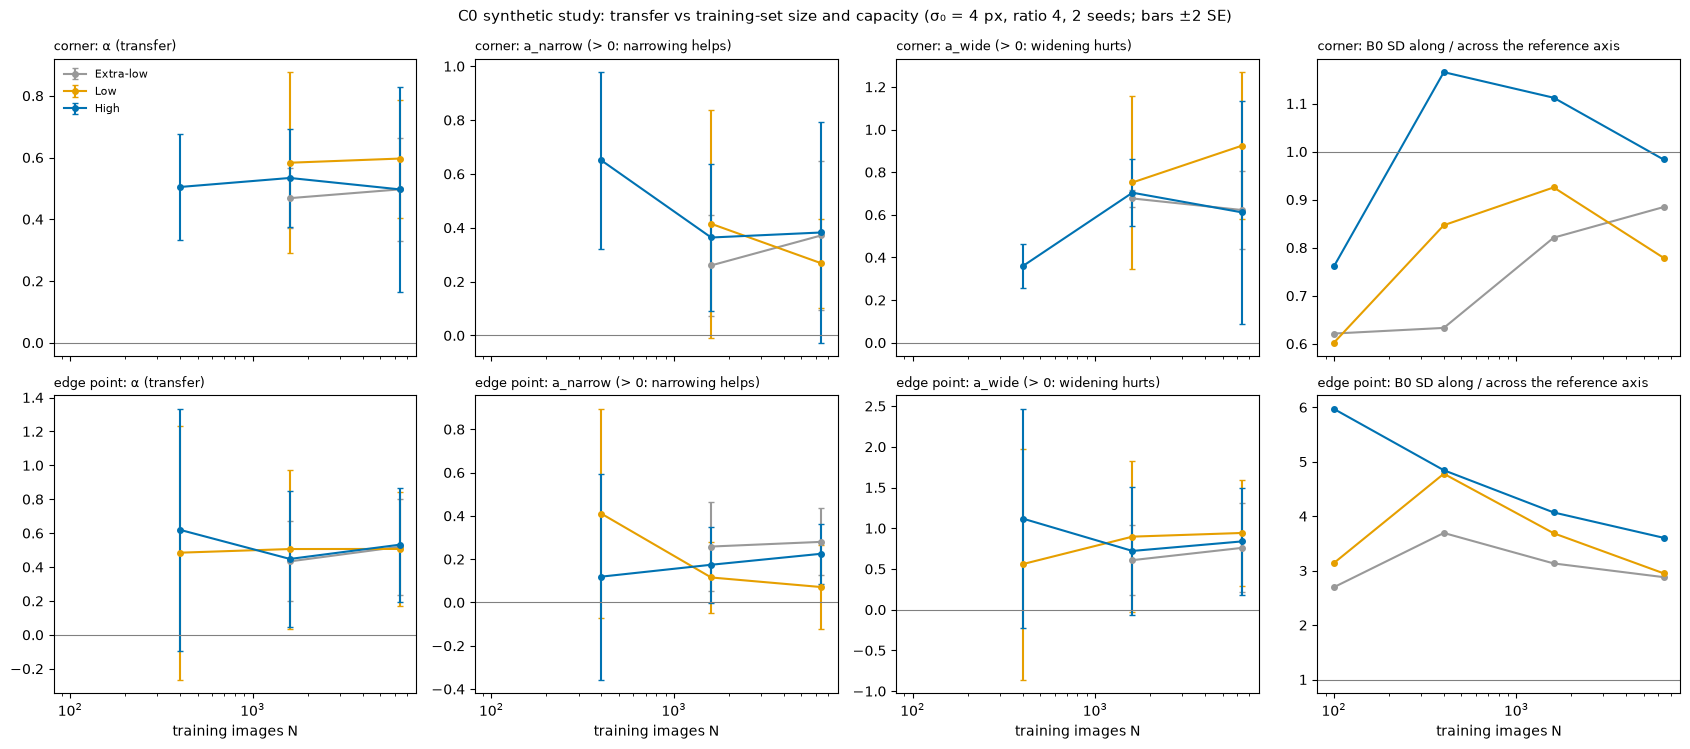

In [4]:
AGG = Path(RUN_ROOT) / "synth_summary"
AGG.mkdir(exist_ok=True)
_LOCK = AGG / ".analysis.lock"
n_done = sum((Path(RUN_ROOT) / r / "DONE").exists() for r in RUN_TABLE.run_id)
print(f"runs done: {n_done} of {len(RUN_TABLE)}")

def _acquire_lock(stale_s=3600):
    if _LOCK.exists() and time.time() - _LOCK.stat().st_mtime > stale_s:
        _LOCK.unlink(missing_ok=True)
    try:
        os.close(os.open(_LOCK, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        return True
    except FileExistsError:
        print("another notebook is running the analysis now; skipped here")
        return False

HAVE_LOCK = n_done == len(RUN_TABLE) and _acquire_lock()
if HAVE_LOCK:
    try:
        H = math.log(2)
        cells = []
        for _, run in RUN_TABLE.iterrows():
            d = Path(RUN_ROOT) / run.run_id
            assert (d / "DONE").read_text().split()[0] == SYNTH_HASH, f"{run.run_id}: protocol differs"
            p = pd.read_csv(d / "predictions_test.csv.gz")
            p["r"] = np.hypot(p.e_u, p.e_v)
            for k, g in p.groupby("landmark"):
                ok = g[g.r <= GROSS_PX]
                cells.append({**run.to_dict(), "landmark": LM_NAMES[k], "fail_rate": 1 - len(ok) / len(g),
                              "mre_px": g.r.mean(), "sd_u": ok.e_u.std(ddof=1), "sd_v": ok.e_v.std(ddof=1)})
        CELLS = pd.DataFrame(cells)
        CELLS.round(5).to_csv(AGG / "synth_cells.csv", index=False)
        b0 = CELLS[CELLS.arm == "B0"].set_index(["tier", "n_train", "seed", "landmark"])
        obs = []
        for _, c in CELLS[CELLS.arm != "B0"].iterrows():
            b = b0.loc[(c.tier, c.n_train, c.seed, c.landmark)]
            usable = c.fail_rate <= 0.05 and b.fail_rate <= 0.05
            long_ax, short_ax = ("u", "v") if c.arm == "Apar" else ("v", "u")
            for axis, ax_name, x in (("long", long_ax, H), ("short", short_ax, -H)):
                obs.append({"tier": c.tier, "n_train": c.n_train, "seed": c.seed, "landmark": c.landmark, "arm": c.arm,
                            "axis": axis, "direction": ax_name, "x": x, "usable": usable,
                            "dlog_sd": math.log(c[f"sd_{ax_name}"] / b[f"sd_{ax_name}"])})
        OBS = pd.DataFrame(obs)
        OBS.round(5).to_csv(AGG / "synth_axis_observations.csv", index=False)
        rows = []
        for (tier, n, lm), g in OBS[OBS.usable].groupby(["tier", "n_train", "landmark"]):
            row = {"tier": tier, "n_train": n, "landmark": lm, "n_obs": len(g)}
            if len(g) >= 4 and g.x.nunique() == 2:
                X = np.column_stack([np.ones(len(g)), g.x])
                bcoef, *_ = np.linalg.lstsq(X, g.dlog_sd.values, rcond=None)
                r = g.dlog_sd.values - X @ bcoef
                se = math.sqrt((r @ r / max(len(g) - 2, 1)) * np.linalg.inv(X.T @ X)[1, 1])
                lg, sh = g[g.axis == "long"].dlog_sd, g[g.axis == "short"].dlog_sd
                row.update({"alpha": bcoef[1], "alpha_se": se, "a_wide": lg.mean() / H,
                            "a_wide_se": lg.std(ddof=1) / math.sqrt(len(lg)) / H if len(lg) > 1 else np.nan,
                            "a_narrow": -sh.mean() / H, "a_narrow_se": sh.std(ddof=1) / math.sqrt(len(sh)) / H if len(sh) > 1 else np.nan})
            rows.append(row)
        RES = pd.DataFrame(rows)
        RES.round(5).to_csv(AGG / "synth_alpha_by_tier_N.csv", index=False)
        B0T = CELLS[CELLS.arm == "B0"].groupby(["tier", "n_train", "landmark"]).agg(mre_px=("mre_px", "mean"), fail=("fail_rate", "mean"),
                                                                                    sd_u=("sd_u", "mean"), sd_v=("sd_v", "mean"))
        B0T["anisotropy_u_over_v"] = B0T.sd_u / B0T.sd_v
        B0T.round(4).to_csv(AGG / "synth_baseline.csv")
        conv = []
        for _, run in RUN_TABLE.iterrows():
            tl = pd.read_csv(Path(RUN_ROOT) / run.run_id / "train_log.csv").dropna(subset=["conv_mre_px"])
            v = tl.conv_mre_px.values
            conv.append({"run_id": run.run_id, "tier": run.tier, "n_train": run.n_train, "arm": run.arm, "conv_mre_final_px": v[-1],
                         "conv_change_last_check": v[-1] / v[-2] - 1 if len(v) > 1 else np.nan})
        CONV = pd.DataFrame(conv)
        CONV.round(4).to_csv(AGG / "synth_convergence.csv", index=False)
        display(CONV.groupby(["tier", "n_train"])[["conv_mre_final_px", "conv_change_last_check"]].mean().round(3))
        FAILS = CELLS.pivot_table(index=["tier", "n_train"], columns="arm", values="fail_rate", aggfunc="mean")
        FAILS.round(4).to_csv(AGG / "synth_fail_rates.csv")

        tiers = list(TIER_BASE)
        col = dict(zip(tiers, ["#999999", "#E69F00", "#0072B2"][-len(tiers):]))
        fig, axs = plt.subplots(2, 4, figsize=(17, 7.6), sharex=True)
        for r, lm in enumerate(LM_NAMES):
            for j, (q, lab) in enumerate((("alpha", "α (transfer)"), ("a_narrow", "a_narrow (> 0: narrowing helps)"),
                                          ("a_wide", "a_wide (> 0: widening hurts)"))):
                ax = axs[r, j]
                for tier in tiers:
                    g = RES[(RES.tier == tier) & (RES.landmark == lm)].sort_values("n_train")
                    if q in g:
                        ax.errorbar(g.n_train, g[q], yerr=2 * g[f"{q}_se"], marker="o", ms=4, capsize=2, color=col[tier], label=tier)
                ax.axhline(0, color="0.5", lw=0.8)
                ax.set_xscale("log"); ax.set_title(f"{lm}: {lab}", fontsize=9, loc="left")
                if r == 1:
                    ax.set_xlabel("training images N")
            ax = axs[r, 3]
            for tier in tiers:
                g = B0T.xs(lm, level="landmark").loc[tier]
                ax.plot(g.index, g.anisotropy_u_over_v, marker="o", ms=4, color=col[tier], label=tier)
            ax.axhline(1, color="0.5", lw=0.8); ax.set_xscale("log")
            ax.set_title(f"{lm}: B0 SD along / across the reference axis", fontsize=9, loc="left")
            if r == 1:
                ax.set_xlabel("training images N")
        axs[0, 0].legend(fontsize=8, frameon=False)
        fig.suptitle(f"C0 synthetic study: transfer vs training-set size and capacity (σ₀ = {SIGMA0_PX:g} px, ratio {RATIO:g}, "
                     f"{len(SEEDS)} seeds; bars ±2 SE)", fontsize=11)
        fig.tight_layout()
        fig.savefig(AGG / "synth_transfer_vs_N.png", dpi=150)
        summary = {"protocol_hash": SYNTH_HASH, "runs": len(RUN_TABLE),
                   "max_fail_rate_B0": float(CELLS[CELLS.arm == "B0"].fail_rate.max()),
                   "alpha_by_tier_N": RES.round(4).to_dict("records")}
        (AGG / "synth_summary.json").write_text(json.dumps(summary, indent=1, default=float))
        display(FAILS.round(3))
        display(B0T.round(3))
        display(RES.pivot_table(index=["landmark", "tier"], columns="n_train", values=["alpha", "a_narrow", "a_wide"]).round(3))
    finally:
        _LOCK.unlink(missing_ok=True)

In [5]:
POD = Path(RUN_ROOT) / "synth_summary_pod"
if POD.exists():
    a = pd.read_csv(POD / "synth_alpha_by_tier_N.csv").set_index(["tier", "n_train", "landmark"]).sort_index()
    b = pd.read_csv(AGG / "synth_alpha_by_tier_N.csv").set_index(["tier", "n_train", "landmark"]).sort_index()
    print("local §9 reproduces the pod's alpha table:", bool(np.allclose(a.alpha, b.alpha, equal_nan=True, atol=1e-4)))

local §9 reproduces the pod's alpha table: True


## 10. Decoder sensitivity (exploratory, added after the first look at §9)

The synthetic errors are sub-pixel (fine SD 0.2–0.8 px), a regime where the sub-pixel decoder itself can respond to the heatmap's
shape: a peak that is flat along one axis is localised less precisely along it, even for the same network. If the transfer in §9 came
from the decoder, it would differ strongly between decoders. All four decoders were stored for every test prediction. The per-image
reference angle is recovered from the stored primary-decoder projection (e_u, e_v), so every decoder is projected on the same axes;
the quadratic decoder must reproduce §9 exactly (asserted).

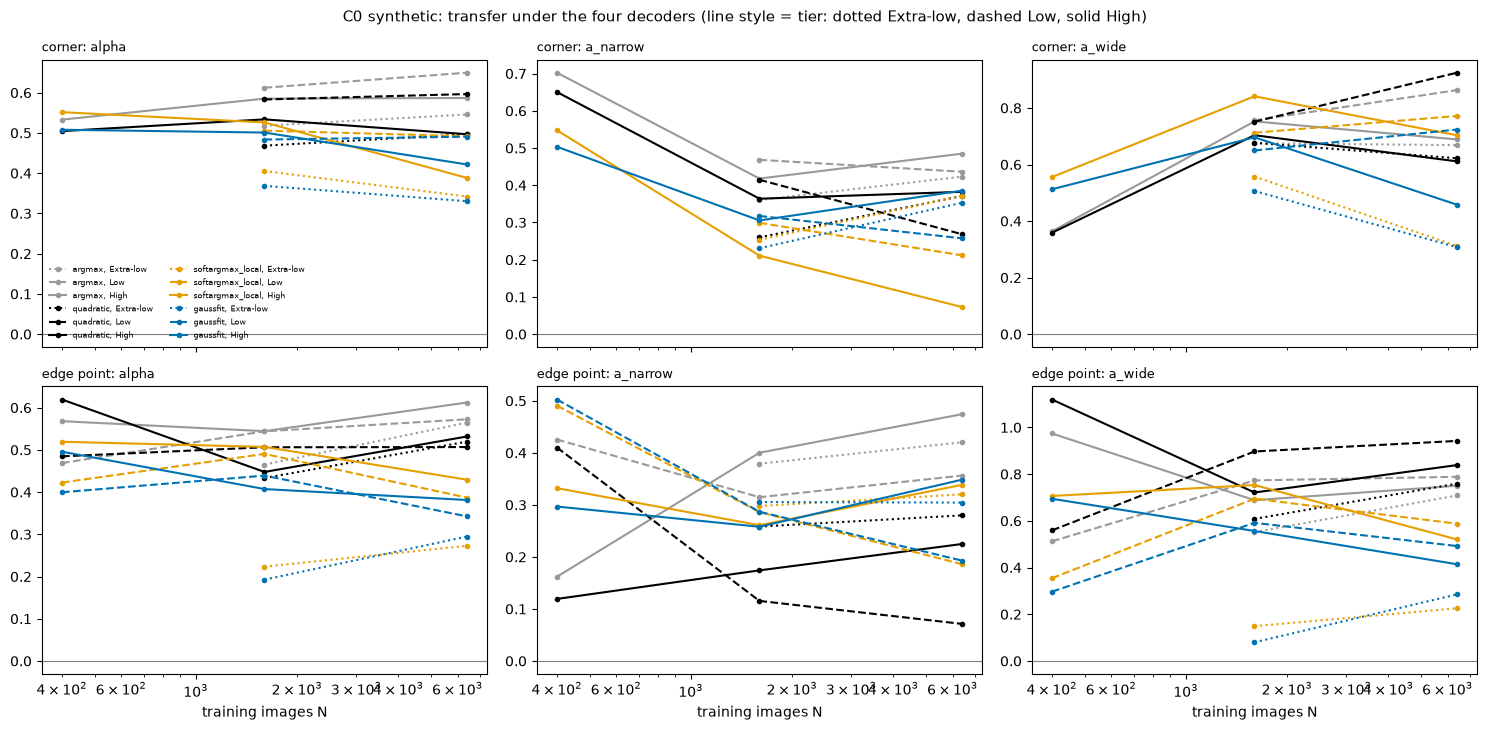

a_narrow           ...     alpha                 
decoder                        argmax gaussfit  ... quadratic softargmax_local
landmark   tier      n_train                    ...                           
corner     Extra-low 1600       0.361    0.231  ...     0.468            0.405
                     6400       0.423    0.353  ...     0.497            0.342
           High      400        0.702    0.503  ...     0.505            0.552
                     1600       0.418    0.306  ...     0.534            0.526
                     6400       0.485    0.385  ...     0.497            0.388
           Low       1600       0.468    0.318  ...     0.583            0.506
                     6400       0.436    0.257  ...     0.597            0.492
edge point Extra-low 1600       0.379    0.305  ...     0.433            0.223
                     6400       0.420    0.304  ...     0.520            0.273
           High      400        0.162    0.297  ...     0.619            0.519
                     1600       0.400    0.258  ...     0.448            0.507
                     6400       0.474    0.348  ...     0.532            0.429
           Low       400        0.426    0.503  ...     0.485            0.423
                     1600       0.315    0.287  ...     0.506            0.490
                     6400       0.356    0.193  ...     0.507            0.387

[15 rows x 8 columns]

In [6]:
DEC = SYNTH_PROTOCOL["decoders"]
PRIMARY = SYNTH_PROTOCOL["primary_decoder"]
LOG2 = math.log(2)

def _preds(rid):
    return pd.read_csv(Path(RUN_ROOT) / rid / "predictions_test.csv.gz")

PHI = {}
for rid in RUN_TABLE.run_id:
    p = _preds(rid)
    ok = np.hypot(p.e_u, p.e_v) > 1e-9
    ph = np.arctan2(p[f"dy_{PRIMARY}"], p[f"dx_{PRIMARY}"]) - np.arctan2(p.e_v, p.e_u)
    for key, val in zip(zip(p.image[ok], p.landmark[ok]), ph[ok]):
        PHI.setdefault(key, val)
    if len(PHI) == N_TEST * K:
        break
assert len(PHI) == N_TEST * K, len(PHI)

dec_cells = []
for _, run in RUN_TABLE.iterrows():
    p = _preds(run.run_id)
    ph = np.array([PHI[(i, k)] for i, k in zip(p.image, p.landmark)])
    for d in DEC:
        u = p[f"dx_{d}"] * np.cos(ph) + p[f"dy_{d}"] * np.sin(ph)
        v = -p[f"dx_{d}"] * np.sin(ph) + p[f"dy_{d}"] * np.cos(ph)
        r = np.hypot(u, v)
        for k in range(K):
            m = (p.landmark == k).values
            ok = m & (r <= GROSS_PX).values
            dec_cells.append({"tier": run.tier, "n_train": run.n_train, "arm": run.arm, "seed": run.seed, "decoder": d,
                              "landmark": LM_NAMES[k], "fail_rate": 1 - ok.sum() / m.sum(),
                              "sd_u": u[ok].std(ddof=1), "sd_v": v[ok].std(ddof=1)})
DCELLS = pd.DataFrame(dec_cells)
_chk = DCELLS[DCELLS.decoder == PRIMARY].merge(CELLS, on=["tier", "n_train", "arm", "seed", "landmark"], suffixes=("", "_s9"))
assert np.allclose(_chk.sd_u, _chk.sd_u_s9, rtol=1e-6) and np.allclose(_chk.sd_v, _chk.sd_v_s9, rtol=1e-6), "decoder table does not reproduce §9"

def slopes(obs):
    rows = []
    for key, g in obs[obs.usable].groupby(["decoder", "tier", "n_train", "landmark"]):
        if len(g) < 4 or g.x.nunique() < 2:
            continue
        X = np.column_stack([np.ones(len(g)), g.x])
        b, *_ = np.linalg.lstsq(X, g.dlog_sd.values, rcond=None)
        lg, sh = g[g.axis == "long"].dlog_sd, g[g.axis == "short"].dlog_sd
        rows.append(dict(zip(["decoder", "tier", "n_train", "landmark"], key), alpha=b[1], a_wide=lg.mean() / LOG2,
                         a_narrow=-sh.mean() / LOG2, n_obs=len(g)))
    return pd.DataFrame(rows)

def axis_obs(cells, by_decoder=True):
    keys = ["tier", "n_train", "seed", "landmark"] + (["decoder"] if by_decoder else [])
    b0 = cells[cells.arm == "B0"].set_index(keys)
    rows = []
    for _, c in cells[cells.arm != "B0"].iterrows():
        b = b0.loc[tuple(c[k] for k in keys)]
        usable = bool(c.fail_rate <= 0.05 and b.fail_rate <= 0.05)
        lo, sh = ("u", "v") if c.arm == "Apar" else ("v", "u")
        for axis, dr, x in (("long", lo, LOG2), ("short", sh, -LOG2)):
            rows.append({**{k: c[k] for k in keys}, "arm": c.arm, "axis": axis, "direction": dr, "x": x, "usable": usable,
                         "sd": c[f"sd_{dr}"], "sd_b0": b[f"sd_{dr}"], "dlog_sd": math.log(c[f"sd_{dr}"] / b[f"sd_{dr}"])})
    return pd.DataFrame(rows)

DOBS = axis_obs(DCELLS)
DSLOPE = slopes(DOBS)
DSLOPE.round(4).to_csv(AGG / "synth_decoder_sensitivity.csv", index=False)
assert np.allclose(DSLOPE[DSLOPE.decoder == PRIMARY].set_index(["tier", "n_train", "landmark"]).alpha.sort_index(),
                   RES.dropna(subset=["alpha"]).set_index(["tier", "n_train", "landmark"]).alpha.sort_index(), atol=1e-9)

fig, axs = plt.subplots(2, 3, figsize=(15, 7.4), sharex=True)
dcol = {"argmax": "#999999", "quadratic": "#000000", "softargmax_local": "#E69F00", "gaussfit": "#0072B2"}
for r, lm in enumerate(LM_NAMES):
    for j, q in enumerate(("alpha", "a_narrow", "a_wide")):
        ax = axs[r, j]
        for d in DEC:
            for tier, ls in zip(TIER_BASE, (":", "--", "-")):
                g = DSLOPE[(DSLOPE.decoder == d) & (DSLOPE.tier == tier) & (DSLOPE.landmark == lm)].sort_values("n_train")
                ax.plot(g.n_train, g[q], ls, marker="o", ms=3, color=dcol[d], label=f"{d}, {tier}" if (r, j) == (0, 0) else None)
        ax.axhline(0, color="0.5", lw=0.8); ax.set_xscale("log")
        ax.set_title(f"{lm}: {q}", fontsize=9, loc="left")
        if r == 1:
            ax.set_xlabel("training images N")
axs[0, 0].legend(fontsize=6, frameon=False, ncol=2)
fig.suptitle("C0 synthetic: transfer under the four decoders (line style = tier: dotted Extra-low, dashed Low, solid High)", fontsize=11)
fig.tight_layout()
fig.savefig(AGG / "synth_decoder_sensitivity.png", dpi=150)
DSLOPE.pivot_table(index=["landmark", "tier", "n_train"], columns="decoder", values=["alpha", "a_narrow"]).round(3)

## 11. The additive-variance model on the synthetic data, and against ISBI (exploratory)

The ISBI analysis (`C0_ISBI2015_additive_variance.ipynb`) found that error variance along a target axis behaves as
SD² = s² + k · σ_d², with k ≈ 0.004–0.005 at both ISBI tiers, and that this one-parameter model explains the weak, one-sided
transfer there because the target term k σ₀² is small next to the baseline error. Here the same model is fitted to the synthetic
usable cells (primary decoder): per tier, a common k with intercepts per (N, landmark), as in the ISBI fit; 95 % interval from a
cluster bootstrap over (N, landmark, seed). k is dimensionless (target and error in the same unit), so the values are directly
comparable with ISBI's. Then: does the ISBI k predict the synthetic transfer?

In [7]:
from scipy import optimize

def g_add(x, k, s0, v0):
    return 0.5 * np.log(np.clip(1 + k * s0 ** 2 * (np.exp(2 * x) - 1) / v0, 1e-9, None))

def fit_k(o, s0, groups):
    x, y, v0 = o.x.values, o.dlog_sd.values, o.sd_b0.values ** 2
    hi = 0.999 * v0[x < 0].min() / ((1 - math.exp(2 * x[x < 0].min())) * s0 ** 2) if (x < 0).any() else 1.0
    def sse(k):
        r = y - g_add(x, k, s0, v0)
        r = r - pd.Series(r).groupby(groups).transform("mean").values
        return float(r @ r)
    res = optimize.minimize_scalar(sse, bounds=(0.0, hi), method="bounded", options={"xatol": 1e-8})
    return res.x, res.fun, hi

def sse_alpha(o, groups):
    x = o.x.values - pd.Series(o.x.values).groupby(groups).transform("mean").values
    y = o.dlog_sd.values - pd.Series(o.dlog_sd.values).groupby(groups).transform("mean").values
    a = (x * y).sum() / (x * x).sum()
    r = y - a * x
    return a, float(r @ r)

UOBS = DOBS[(DOBS.decoder == PRIMARY) & DOBS.usable].reset_index(drop=True)
rng = np.random.default_rng(11)
krows = []
for tier, o in UOBS.groupby("tier"):
    o = o.reset_index(drop=True)
    grp = (o.n_train.astype(str) + "_" + o.landmark).values
    k, sse_k, hi = fit_k(o, SIGMA0_PX, grp)
    a, sse_a = sse_alpha(o, grp)
    n, p_extra = len(o), len(set(grp))
    clusters = (o.n_train.astype(str) + "_" + o.landmark + "_" + o.seed.astype(str)).values
    uc = np.unique(clusters)
    boots = []
    for _ in range(300):
        pick = rng.choice(uc, len(uc), replace=True)
        ob = pd.concat([o[clusters == c].assign(_g=f"{j}") for j, c in enumerate(pick)], ignore_index=True)
        boots.append(fit_k(ob, SIGMA0_PX, (ob.n_train.astype(str) + "_" + ob.landmark + "_" + ob._g).values)[0])
    krows.append({"tier": tier, "n_obs": n, "k": k, "k_ci95_low": np.percentile(boots, 2.5), "k_ci95_high": np.percentile(boots, 97.5),
                  "k_upper_bound": hi, "alpha_common": a,
                  "aic_additive": n * math.log(sse_k / n) + 2 * (1 + p_extra), "aic_log_linear": n * math.log(sse_a / n) + 2 * (1 + p_extra)})
KSYN = pd.DataFrame(krows).set_index("tier")
KSYN.round(5).to_csv(AGG / "synth_additive_k.csv")

ISBI_K_FILE = Path(RUN_ROOT).parent / "analyses" / "additive_variance" / "additive_model_k.json"
KISBI = json.loads(ISBI_K_FILE.read_text()) if ISBI_K_FILE.exists() else {}
print("ISBI k:", {t: round(v["k"], 5) for t, v in KISBI.items()} if KISBI else "not found (run C0_ISBI2015_additive_variance first)")

# prediction of the synthetic r = 4 cell means with each k (own tier, ISBI High, ISBI Medium), no intercepts
pred_rows = []
cm = UOBS.groupby(["tier", "n_train", "landmark", "axis", "direction"]).agg(x=("x", "first"), observed=("dlog_sd", "mean"),
                                                                           v0=("sd_b0", lambda s: np.mean(s ** 2))).reset_index()
for name, kval in [("own tier k", None)] + [(f"ISBI {t} k", v["k"]) for t, v in KISBI.items()]:
    kk = cm.tier.map(KSYN.k) if kval is None else kval
    pred = 0.5 * np.log(np.clip(1 + kk * SIGMA0_PX ** 2 * (np.exp(2 * cm.x) - 1) / cm.v0, 1e-9, None))
    pred_rows.append(cm.assign(model=name, predicted=pred))
PRED = pd.concat(pred_rows, ignore_index=True)
PRED.round(4).to_csv(AGG / "synth_additive_predictions.csv", index=False)
rmse = PRED.groupby(["model", "axis"]).apply(lambda g: math.sqrt(((g.observed - g.predicted) ** 2).mean()), include_groups=False).unstack()
display(KSYN.round(5))
rmse.round(4)

ISBI k: {'High': 0.00496, 'Medium': 0.00434}


,n_obs,k,k_ci95_low,k_ci95_high,k_upper_bound,alpha_common,aic_additive,aic_log_linear
tier,,,,,,,,
Extra-low,30,0.00380,0.00339,0.00597,0.00520,0.48025,-89.78479,-92.47794
High,44,0.00149,0.00131,0.00242,0.00193,0.52392,-73.20490,-78.49121
Low,38,0.00196,0.00164,0.00349,0.00242,0.53812,-66.30902,-70.92293


axis,long,short
model,,
ISBI High k,0.2934,3.7382
ISBI Medium k,0.3114,3.2511
own tier k,0.4265,0.2495


## 12. One picture for both datasets: transfer against the size of the target relative to the error (exploratory)

Ratio-4 arm A cells only (long axis 2 σ₀, short axis σ₀/2), usable cells, primary decoder. x = σ₀ / SD_B0 along the axis: how large
the round target is compared with the baseline error in that direction (no fitted parameter). y = mean Δ log SD vs the paired B0.
Lines: the additive model, Δ = ½ log(1 + k (σ_d²/σ₀² − 1) (σ₀/SD_B0)²), for the fitted k values. ISBI points come from the arm A
axis observations of both tiers (`weights/C0/ISBI2015_<tier>/arm_A_summary/`).

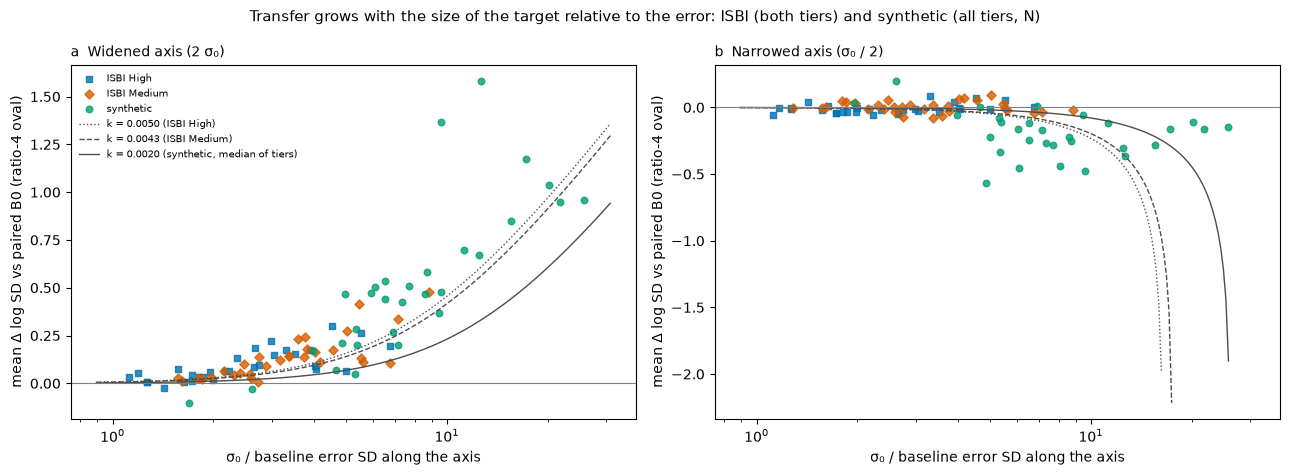

rho_median  dlog_mean   n
dataset     axis                            
ISBI High   long        2.289      0.095  30
            short       2.289     -0.009  30
ISBI Medium long        3.362      0.136  31
            short       3.174      0.004  31
synthetic   long        7.241      0.529  30
            short       7.241     -0.197  30

In [8]:
pts = []
syn = UOBS.groupby(["tier", "n_train", "landmark", "axis", "direction"]).agg(dlog=("dlog_sd", "mean"),
                                                                            sd0=("sd_b0", lambda s: math.sqrt(np.mean(s ** 2)))).reset_index()
syn["rho"] = SIGMA0_PX / syn.sd0
pts.append(syn.assign(dataset="synthetic"))
ISBI_S0 = {"High": 5.0 * 0.3125, "Medium": 5.0 * 2 ** 0.5 * 0.3125}
for t, s0mm in ISBI_S0.items():
    f = Path(RUN_ROOT).parent / f"ISBI2015_{t}" / "arm_A_summary" / "arm_A_axis_observations.csv"
    if not f.exists():
        continue
    o = pd.read_csv(f)
    o = o[(o.decoder == "quadratic") & o.usable.astype(bool) & np.isclose(o.ratio, 4.0)]
    g = o.groupby(["landmark", "axis", "direction"]).agg(dlog=("dlog_sd", "mean"), sd0=("sd_b0", lambda s: math.sqrt(np.mean(s ** 2)))).reset_index()
    g["rho"] = s0mm / g.sd0
    pts.append(g.assign(dataset=f"ISBI {t}", tier=t))
PTS = pd.concat(pts, ignore_index=True)
PTS.round(4).to_csv(AGG / "transfer_vs_target_to_error_ratio.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
mk = {"synthetic": "o", "ISBI High": "s", "ISBI Medium": "D"}
cl = {"synthetic": "#009E73", "ISBI High": "#0072B2", "ISBI Medium": "#D55E00"}
rr = np.logspace(np.log10(PTS.rho.min() * 0.8), np.log10(PTS.rho.max() * 1.2), 200)
klines = {f"k = {v['k']:.4f} (ISBI {t})": v["k"] for t, v in KISBI.items()}
klines.update({f"k = {KSYN.k.median():.4f} (synthetic, median of tiers)": float(KSYN.k.median())})
for ax, axis, ratio_sq in ((axs[0], "long", 4.0), (axs[1], "short", 0.25)):
    for ds, g in PTS[PTS.axis == axis].groupby("dataset"):
        ax.scatter(g.rho, g.dlog, s=22, marker=mk[ds], color=cl[ds], alpha=0.8, label=ds)
    for (lab, kv), ls in zip(klines.items(), (":", "--", "-")):
        arg = 1 + kv * (ratio_sq - 1) * rr ** 2
        ax.plot(rr[arg > 0], 0.5 * np.log(arg[arg > 0]), ls, color="0.3", lw=1, label=lab)
    ax.axhline(0, color="0.5", lw=0.8); ax.set_xscale("log")
    ax.set_xlabel("σ₀ / baseline error SD along the axis")
    ax.set_ylabel("mean Δ log SD vs paired B0 (ratio-4 oval)")
    ax.set_title(f"{'a  Widened axis (2 σ₀)' if axis == 'long' else 'b  Narrowed axis (σ₀ / 2)'}", loc="left", fontsize=10)
axs[0].legend(fontsize=7, frameon=False)
fig.suptitle("Transfer grows with the size of the target relative to the error: ISBI (both tiers) and synthetic (all tiers, N)", fontsize=11)
fig.tight_layout()
fig.savefig(AGG / "transfer_vs_target_to_error_ratio.png", dpi=150)
PTS.groupby(["dataset", "axis"]).agg(rho_median=("rho", "median"), dlog_mean=("dlog", "mean"), n=("dlog", "size")).round(3)